Code for Analysis 3: 

--> scRNAseq comparison to null model 

In [2]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

%matplotlib inline

# ---- configuration ----------------------------------------------------------
INPUT_DIR = Path("inputs")             # written by 00_preprocess.ipynb
REGULON_FILES = {                      # name -> path (.gmt, or CSV with columns tf,target); leave empty to skip
     "TF Link":   "../data/TFLink_Caenorhabditis_elegans_interactions_All_GMT_proteinName_v1.0.gmt",
}
SEED = 0
TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
OUT = Path("../figures/analysis_3")
XS = [50, 100, 250, 500, 1000, 2000]   # top-X DE genes per neuron
K_COMMUNITIES = 4
N_PERM = 200                           # label permutations for the score null
OUT.mkdir(exist_ok=True)

In [7]:
# Helper Functions
def cpm(counts):
    return counts / counts.sum(axis=0) * 1e6


def one_vs_all_log2fc(counts, pseudo=1.0):
    """log2 fold change of each column (CPM) vs the mean of all other columns."""
    c = cpm(counts)
    n = c.shape[1]
    rest = (c.sum(axis=1).values[:, None] - c.values) / (n - 1)
    return pd.DataFrame(np.log2((c.values + pseudo) / (rest + pseudo)),
                        index=c.index, columns=c.columns)


def build_connectome(edges, meta_types):
    G = nx.Graph()
    G.add_nodes_from(meta_types.index)
    for r in edges.itertuples(index=False):
        a, b = r[0], r[1]
        w = r[2] if len(r) > 2 else 1.0
        if a in G and b in G and a != b:
            if G.has_edge(a, b):
                G[a][b]["weight"] += w
            else:
                G.add_edge(a, b, weight=w)
    nx.set_node_attributes(G, meta_types.to_dict(), "type")
    return G


def read_gene_sets(path):
    p, sets = Path(path), {}
    if p.suffix.lower() == ".gmt":
        for line in open(p):
            f = line.rstrip("\n").split("\t")
            if len(f) >= 3:
                sets[f[0]] = {g for g in f[2:] if g}
    else:
        df = pd.read_csv(p)
        tf, tg = df.columns[:2]
        for name, sub in df.groupby(tf):
            sets[str(name)] = set(sub[tg].astype(str)) | {str(name)}
    return sets


def expression_weights(lfc, X):
    """Dense symmetric weight matrix (nodes x nodes) from top-X log2FC genes."""
    M = lfc.values
    X = min(X, M.shape[0])
    top = np.zeros(M.shape, dtype=bool)
    np.put_along_axis(top, np.argsort(-M, axis=0)[:X], True, axis=0)
    L = np.where(top, M, 0.0)
    T = top.astype(float)
    W = (L.T @ T + T.T @ L) / 2.0
    np.fill_diagonal(W, 0.0)
    return W


def threshold_graph(W, nodes, types, n_edges):
    iu = np.triu_indices_from(W, k=1)
    w = W[iu]
    order = np.argsort(-w)[:n_edges]
    order = order[w[order] > 0]
    G = nx.Graph()
    G.add_nodes_from(nodes)
    for k in order:
        G.add_edge(nodes[iu[0][k]], nodes[iu[1][k]], weight=float(w[k]))
    nx.set_node_attributes(G, types.to_dict(), "type")
    return G


def groupmate_score(null_labels, comm_labels):
    """Per-neuron fraction of its null-model group-mates that share its community."""
    nl, cl = np.asarray(null_labels), np.asarray(comm_labels)
    sc = np.full(len(nl), np.nan)
    for i in range(len(nl)):
        mates = np.where((nl == nl[i]) & (np.arange(len(nl)) != i))[0]
        if len(mates):
            sc[i] = np.mean(cl[mates] == cl[i])
    return sc


def community_eval(null_labels, comm, n_perm, rng):
    sc = groupmate_score(null_labels, comm)
    obs = np.nanmean(sc)
    null = [np.nanmean(groupmate_score(null_labels, rng.permutation(comm))) for _ in range(n_perm)]
    return sc, dict(score=obs, null_mean=np.mean(null),
                    p=(1 + np.sum(np.array(null) >= obs)) / (1 + n_perm),
                    ARI=adjusted_rand_score(null_labels, comm),
                    NMI=normalized_mutual_info_score(null_labels, comm))


def analysis3(conn, nets, types, k, n_perm, out, seed):
    rng = np.random.default_rng(seed)
    nodes = list(conn.nodes)
    null_labels = types.reindex(nodes).values
    rows = []

    comms = nx.community.greedy_modularity_communities(conn, weight="weight", cutoff=k, best_n=k)
    lab = {n: i for i, c in enumerate(comms) for n in c}
    _, st = community_eval(null_labels, np.array([lab[n] for n in nodes]), n_perm, rng)
    rows.append(dict(source="connectome", X=np.nan, **st))

    per_neuron = {}
    for (sname, X), (G, W) in nets.items():
        A = np.clip(W, 0.0, None) + 1e-6   # affinities must be non-negative (W can be <0 when X ~ #genes)
        np.fill_diagonal(A, 0.0)
        comm = SpectralClustering(n_clusters=k, affinity="precomputed", random_state=seed,
                                  assign_labels="kmeans").fit_predict(A)
        sc, st = community_eval(null_labels, comm, n_perm, rng)
        rows.append(dict(source=sname, X=X, **st))
        per_neuron[f"{sname}_X{X}"] = sc
    res = pd.DataFrame(rows)
    res.to_csv(out / "analysis3_community_scores.csv", index=False)
    pd.DataFrame(per_neuron, index=nodes).to_csv(out / "analysis3_per_neuron_scores.csv")

    fig, ax = plt.subplots(figsize=(6, 4))
    for sname in res.source.unique():
        if sname == "connectome":
            continue
        d = res[res.source == sname].sort_values("X")
        ax.plot(d.X, d.score, marker="o", label=sname)
    ax.axhline(res.loc[res.source == "connectome", "score"].iloc[0], color="k", ls="--", label="connectome")
    ax.set_xlabel("X (top DE genes per neuron)")
    ax.set_ylabel("network-wide group-mate score")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(out / "analysis3_community_score_vs_X.png", dpi=150)
    plt.show()
    return res


def build_nets(conn, lfc, types, sources, Xs):
    """Expression networks, density-matched to the connectome. Returns {(source, X): (graph, weight matrix)}."""
    nodes, n_edges, nets = list(conn.nodes), conn.number_of_edges(), {}
    for sname, genes in sources.items():
        sub = lfc if genes is None else lfc.loc[lfc.index.intersection(list(genes))]
        if sub.shape[0] < 5:
            print(f"skipping source {sname}: <5 genes overlap")
            continue
        for X in Xs:
            if X >= sub.shape[0]:
                print(f"skipping {sname} X={X}: X >= number of genes ({sub.shape[0]}), top-X is not selective")
                continue
            W = expression_weights(sub, X)
            nets[(sname, X)] = (threshold_graph(W, nodes, types, n_edges), W)
    return nets

In [4]:
# Data Load
meta = pd.read_csv(INPUT_DIR / "neurons.csv")
counts = pd.read_csv(INPUT_DIR / "counts.csv", index_col=0)
meta["neuron"] = meta["neuron"].astype(str)
nodes = [n for n in meta["neuron"] if n in counts.columns]
meta = meta.set_index("neuron").loc[nodes]
types = meta["type"]
counts = counts[nodes]
counts = counts.loc[counts.sum(axis=1) > 0]
print(f"{len(nodes)} neurons, {counts.shape[0]} genes")
print(types.value_counts().to_dict())
lfc = one_vs_all_log2fc(counts)          # genes x neurons, one-vs-all log2FC on CPM

edges = pd.read_csv(INPUT_DIR / "edges.csv")
conn = build_connectome(edges, types)
print(f"connectome (undirected projection): {conn.number_of_edges()} edges")

# gene sources for expression networks: all genes, plus each regulon collection
sources, reg_sets = {"all_genes": None}, {}
reg_files = {nm: read_gene_sets(p) for nm, p in REGULON_FILES.items()}
for name, sets in reg_files.items():
    sources[f"regulon_{name}"] = set().union(*sets.values())
    reg_sets.update({f"{name}:{k}": v for k, v in sets.items()})
if len(reg_files) > 1:
    sources["regulon_combined"] = set().union(*reg_sets.values())
print("gene sources:", list(sources))

126 neurons, 13546 genes
{'interneuron': 45, 'sensory': 39, 'motor': 28, 'pharyngeal': 14}
connectome (undirected projection): 1474 edges
gene sources: ['all_genes', 'regulon_TF Link']


In [5]:
# Build Networks
nets = build_nets(conn, lfc, types, sources, XS)
print(len(nets), "networks built")

12 networks built


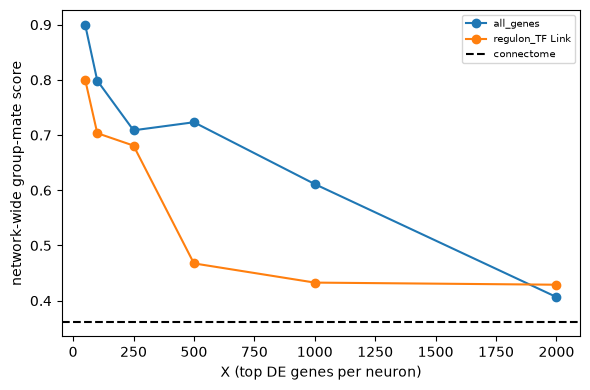

,source,X,score,null_mean,p,ARI,NMI
0,connectome,NaN,0.362,0.275,0.005,0.039,0.153
1,all_genes,50.0,0.900,0.892,0.005,-0.001,0.087
2,all_genes,100.0,0.799,0.719,0.005,0.092,0.264
3,all_genes,250.0,0.709,0.610,0.005,0.112,0.321
4,all_genes,500.0,0.723,0.477,0.005,0.307,0.535
5,all_genes,1000.0,0.611,0.392,0.005,0.294,0.408
6,all_genes,2000.0,0.407,0.309,0.005,0.108,0.211
7,regulon_TF Link,50.0,0.800,0.696,0.005,0.082,0.264
8,regulon_TF Link,100.0,0.703,0.579,0.005,0.141,0.351
9,regulon_TF Link,250.0,0.681,0.420,0.005,0.314,0.500


In [8]:
# Run Analysis 3
a3 = analysis3(conn, nets, types, K_COMMUNITIES, N_PERM, OUT, SEED)
a3.round(3)